In [3]:
# Import required libraries
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

In [11]:
# Load CIFAR-10 dataset directly from Keras
(X_train, y_train), (X_test, y_test) = tf.keras.datasets.cifar10.load_data()

# Display dataset shapes
print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 814s 5us/step
Training Data: (50000, 32, 32, 3)
Testing Data: (10000, 32, 32, 3)


In [12]:
# Normalize pixel values between 0 and 1
X_train = X_train/ 255.0
X_test = X_test/ 255.0

# Flatten images into one-dimensional arrays
X_train = X_train.reshape(-1, 3072)
X_test = X_test.reshape(-1, 3072)

# Convert labels into one-dimensional arrays
y_train = y_train.flatten()
y_test = y_test.flatten()

print("Training Shape:", X_train.shape)
print("Testing Shape:", X_test.shape)

Training Shape: (50000, 3072)
Testing Shape: (10000, 3072)


In [13]:
# Create Feedforward Neural Network
model = tf.keras.Sequential([
    # Input layer
    tf.keras.layers.Input(shape=(3072,)),

    # Hidden layers
    tf.keras.layers.Dense(256, activation='relu'),
    tf.keras.layers.Dense(128, activation='relu'),

    # Output layer for 10 categories
    tf.keras.layers.Dense(10, activation='softmax')
])

# Display model summary
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense (Dense)                        │ (None, 256)                 │         786,688 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 128)                 │          32,896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 10)                  │           1,290 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 820,874 (3.13 MB)

 Trainable params: 820,874 (3.13 MB)

 Non-trainable params: 0 (0.00 B)

In [14]:
# Compile the FNN model
model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

In [15]:
# Train the model
model.fit(X_train, y_train,
          epochs=10,
          batch_size=128)

Epoch 1/10
391/391 ━━━━━━━━━━━━━━━━━━━━ 4s 7ms/step - accuracy: 0.3191 - loss: 1.8975
Epoch 2/10
391/391 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.3948 - loss: 1.6979
Epoch 3/10
391/391 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.4256 - loss: 1.6135
Epoch 4/10
391/391 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.4452 - loss: 1.5565
Epoch 5/10
391/391 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.4601 - loss: 1.5208
Epoch 6/10
391/391 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.4720 - loss: 1.4773
Epoch 7/10
391/391 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.4850 - loss: 1.4529
Epoch 8/10
391/391 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.4909 - loss: 1.4282
Epoch 9/10
391/391 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.4991 - loss: 1.4068
Epoch 10/10
391/391 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.5087 - loss: 1.3807


In [16]:
# Evaluate model on testing data
test_loss, test_accuracy = model.evaluate(X_test, y_test)

# Display testing accuracy
print("Testing Accuracy:", test_accuracy * 100, "%")

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.4921 - loss: 1.4360
Testing Accuracy: 49.21000003814697 %


313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step


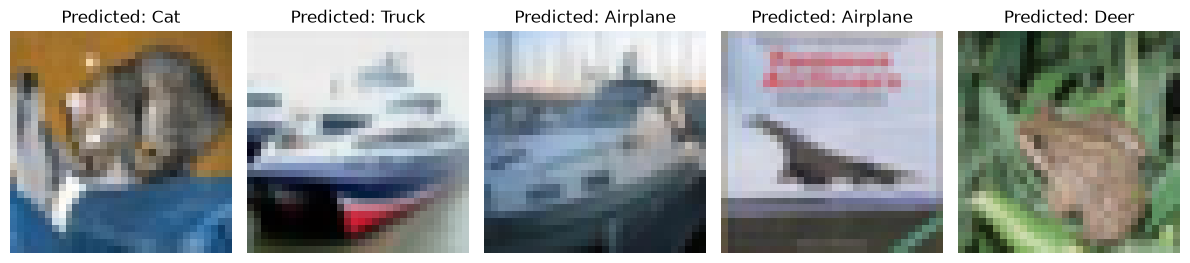

In [17]:
# Define the ten CIFAR-10 class names
class_names = ['Airplane', 'Automobile', 'Bird', 'Cat', 'Deer',
               'Dog', 'Frog', 'Horse', 'Ship', 'Truck']

# Predict test images
predictions = model.predict(X_test)

# Get predicted class numbers
predicted_labels = np.argmax(predictions, axis=1)

# Display five test images with predicted labels
plt.figure(figsize=(12, 5))

for i in range(5):
    plt.subplot(1, 5, i+1)
    plt.imshow(X_test[i].reshape(32, 32, 3))
    plt.title("Predicted: " + class_names[predicted_labels[i]])
    plt.axis('off')

plt.tight_layout()
plt.show()

In [ ]:
# Construct a Feedforward Neural Network to recognize different ASL
# alphabet hand gestures. Train the model and display training accuracy,
# testing accuracy and loss graph. Use – Dataset - Sign Language MNIST
# 14.Develop an FNN model to classify images into ten different object
# categories. Perform preprocessing, model training and testing, and
# display predicted class labels. Use – Dataset - CIFAR-10